# Đ18 — Ước lượng nhịp tim từ BVP cổ tay

**Sinh viên:** Trần Tiến Thịnh — **MSSV:** 22110236  
Notebook cuối kỳ này **đánh giá lại checkpoint đã huấn luyện**, kiểm tra hash và tái tính metric trên tập test. ECG chỉ dùng để tạo HR tham chiếu; đầu vào mô hình là BVP.

## Giao thức đã khóa

- WESAD; train S2–S10, validation S11/S13, test S14–S17 (không trùng người).
- Cửa sổ 8 s, bước 2 s; BVP 64→32 Hz, Butterworth bậc 4, 0,5–8 Hz.
- ECG 5–25 Hz và detector đỉnh R thích nghi (không gọi là Pan–Tompkins).
- Metric chính: trung bình MAE theo người (MAE_macro). Test không được dùng để chọn checkpoint.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'configs' / 'final.yaml').exists():
    raise RuntimeError('Hãy chạy notebook từ thư mục gốc của dự án.')
from src.common import load_config, load_processed
from src.model import make_model
from src.train import predict, make_prediction_frame
from src.metrics import summarize_predictions
cfg = load_config(ROOT / 'configs' / 'final.yaml')
metadata, arrays, manifest = load_processed(cfg)
print('Config hash  :', cfg['_config_hash'])
print('Manifest hash:', manifest['manifest_hash'])
print('Shape BVP     :', arrays['bvp_normalized'].shape)

Config hash  : a9c5a3bfb869a6b473307e3c61b7d4e7b5d23ffe37f3cd8406d7612d1172bf0a
Manifest hash: bcc3bd93f84648772e6fad66980cbbcafa93c381ef3724b7d82aeff013841bd8
Shape BVP     : (16422, 256)


In [2]:
summary = json.loads((ROOT/'data/processed/wesad_d18_v2/preprocessing_summary.json').read_text(encoding='utf-8'))
assert summary['manifest_hash'] == manifest['manifest_hash']
assert summary['checks']['finite'] and summary['checks']['alignment']
overview = pd.DataFrame({
    'Số cửa sổ': [summary['windows_before_qc'], summary['windows_kept'], summary['windows_rejected']],
}, index=['Trước QC', 'Giữ lại', 'Loại'])
display(overview)
display(metadata.groupby(['split','condition']).size().unstack(fill_value=0))

,Số cửa sổ
Trước QC,43385
Giữ lại,16422
Loại,26963


condition,Amusement,Baseline,Stress
split,,,
test,730,2347,1367
train,1640,5229,2901
validation,369,1174,665


## Kết quả E0/E1/E2 và ablation

Sai số dưới đây đều lấy từ cùng manifest v2. Độ lệch chuẩn của CNN là độ lệch chuẩn mẫu qua ba seed 42/123/999.

In [3]:
result_table = pd.read_csv(ROOT/'outputs/tables/overall_results_v2.csv')
display(result_table.round(3))
best = result_table.loc[result_table['mae_macro_mean_bpm'].idxmin()]
print(f"Cấu hình có MAE_macro thấp nhất trong các run đã chạy: {best['method']} = {best['mae_macro_mean_bpm']:.3f} BPM")

,method,seeds,mae_macro_mean_bpm,mae_macro_std_bpm,pooled_mae_mean_bpm,pooled_rmse_mean_bpm,pearson_mean
0,E0,0,17.768,NaN,17.762,26.302,0.000
1,E1,0,13.637,NaN,13.642,26.112,0.476
2,A0,3,8.867,0.253,8.865,14.777,0.835
3,A1,3,9.139,0.095,9.134,15.953,0.782
4,A3,3,8.280,0.328,8.279,13.859,0.851


Cấu hình có MAE_macro thấp nhất trong các run đã chạy: A3 = 8.280 BPM


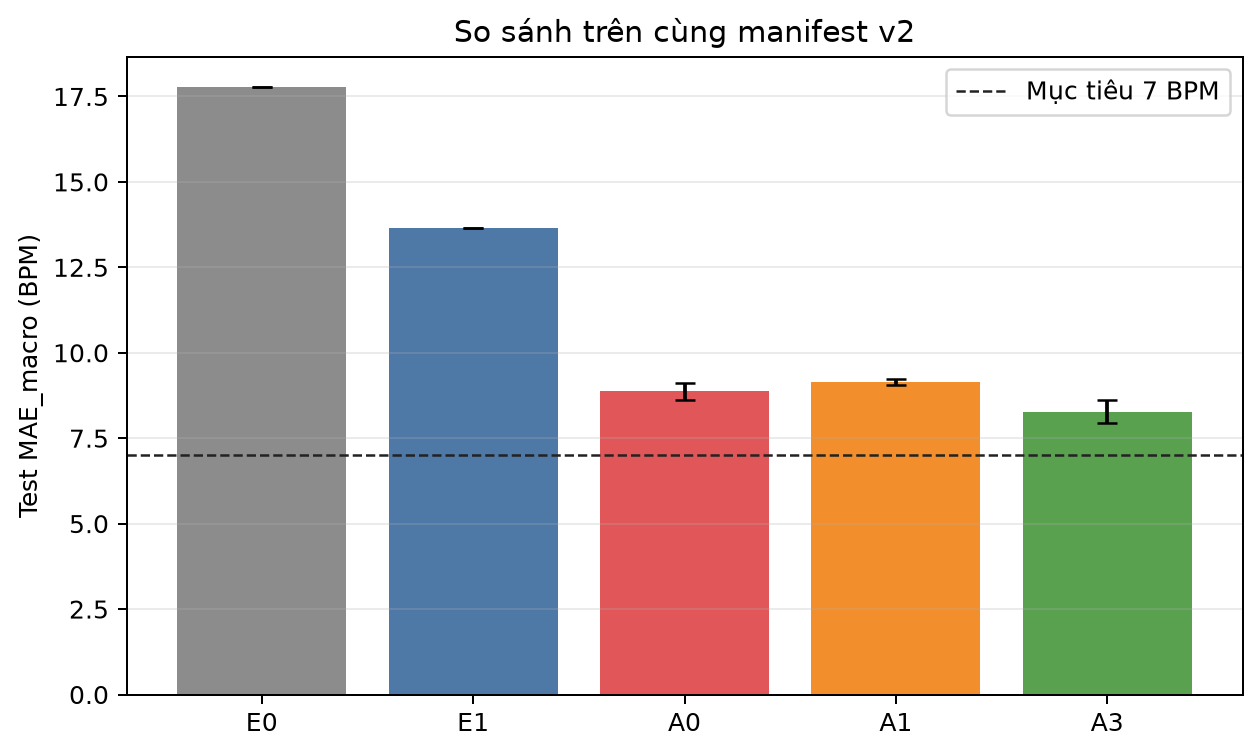

In [4]:
display(Image(filename=str(ROOT/'outputs/figures/overall_mae_macro.png'), width=800))

## Tái tính độc lập A0, seed 42

Cell này nạp `best.pt`, chạy suy luận lại toàn bộ 4.444 cửa sổ test và so khớp với metric đã lưu. Đây là đường đánh giá; không khởi động huấn luyện.

In [5]:
run_dir = ROOT/'outputs/runs/A0_seed42'
saved = json.loads((run_dir/'metrics.json').read_text(encoding='utf-8'))
checkpoint = torch.load(run_dir/'best.pt', map_location='cpu', weights_only=False)
assert checkpoint['manifest_hash'] == manifest['manifest_hash']
assert checkpoint['config_hash'] == cfg['_config_hash']
model = make_model(cfg, 'A0')
model.load_state_dict(checkpoint['model_state'])
test_mask = metadata['split'].eq('test').to_numpy()
pred = predict(model, arrays['bvp_normalized'][test_mask], cfg['training']['batch_size'], torch.device('cpu'))
frame = make_prediction_frame(metadata, test_mask, pred)
recomputed = summarize_predictions(frame, 'hr_pred_bpm')
expected = saved['metrics']['test']['mae_macro_bpm']
assert abs(recomputed['mae_macro_bpm'] - expected) < 1e-6
pd.DataFrame([{
    'MAE_macro (BPM)': recomputed['mae_macro_bpm'],
    'MAE pooled (BPM)': recomputed['pooled']['mae_bpm'],
    'RMSE pooled (BPM)': recomputed['pooled']['rmse_bpm'],
    'Pearson r': recomputed['pooled']['pearson_r'],
    'Bias (BPM)': recomputed['pooled']['bias_bpm'],
}]).round(3)

,MAE_macro (BPM),MAE pooled (BPM),RMSE pooled (BPM),Pearson r,Bias (BPM)
0,8.914,8.914,15.143,0.826,-4.747


In [6]:
condition = pd.DataFrame(recomputed['by_condition'])[['condition','n_windows','mae_macro_bpm','rmse_macro_bpm']]
subject = pd.DataFrame(recomputed['by_subject'])[['subject','n_windows','mae_bpm','rmse_bpm','bias_bpm','pearson_r']]
display(condition.round(3))
display(subject.round(3))

,condition,n_windows,mae_macro_bpm,rmse_macro_bpm
0,Amusement,730,3.465,4.701
1,Baseline,2347,3.862,5.352
2,Stress,1367,20.548,23.933


,subject,n_windows,mae_bpm,rmse_bpm,bias_bpm,pearson_r
0,S14,1104,9.548,17.332,-6.639,0.813
1,S15,1108,3.939,5.405,-0.916,0.530
2,S16,1102,12.253,19.153,-6.800,0.846
3,S17,1130,9.917,14.896,-4.655,0.863


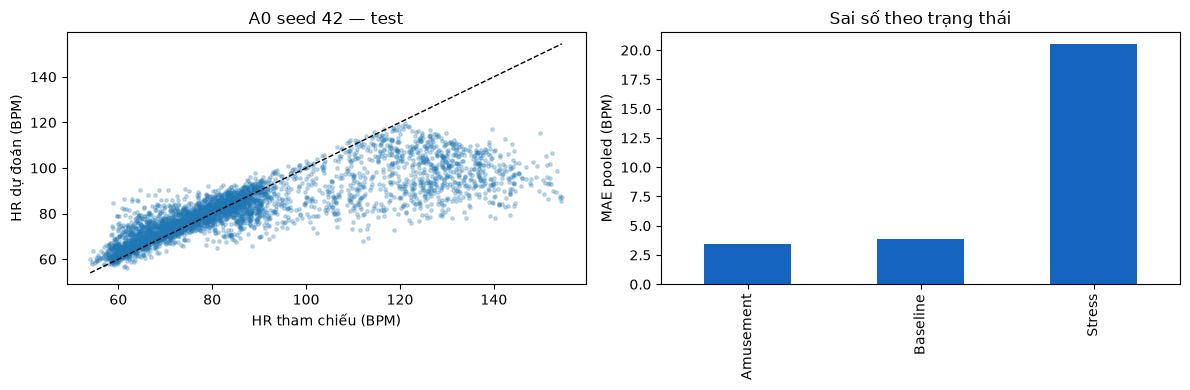

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(frame.hr_ref_bpm, frame.hr_pred_bpm, s=6, alpha=.25)
lims = [min(frame.hr_ref_bpm.min(), frame.hr_pred_bpm.min()), max(frame.hr_ref_bpm.max(), frame.hr_pred_bpm.max())]
axes[0].plot(lims, lims, '--', color='black', lw=1)
axes[0].set(xlabel='HR tham chiếu (BPM)', ylabel='HR dự đoán (BPM)', title='A0 seed 42 — test')
frame.assign(abs_error=frame.error_bpm.abs()).groupby('condition').abs_error.mean().sort_values().plot.bar(ax=axes[1], color='#1565C0')
axes[1].set(ylabel='MAE pooled (BPM)', xlabel='', title='Sai số theo trạng thái')
plt.tight_layout(); plt.show()

## Diễn giải và giới hạn

- A0 giảm MAE_macro khoảng **35,0%** so với FFT, đạt mục tiêu giảm ≥20%, nhưng chưa đạt ngưỡng tuyệt đối 7 BPM.
- A3 (MSE) tốt hơn A0 trong ba seed đã chạy; đây là kết quả thực nghiệm, không phải lựa chọn sau khi xem test.
- Lỗi lớn tập trung ở stress và khác biệt giữa người, đặc biệt S16; HR tham chiếu vẫn là nhãn tự động từ ECG.
- Các hình scatter/timeline dùng seed 42 được cố định; ca lỗi được chọn trên validation, không chọn từ test.

In [8]:
benchmark = json.loads((ROOT/'outputs/benchmark_cpu.json').read_text(encoding='utf-8'))
pd.DataFrame([{
    'Network median (ms)': benchmark['network_only']['median_ms'],
    'Network P95 (ms)': benchmark['network_only']['p95_ms'],
    'Ước lượng end-to-end median (ms)': benchmark['end_to_end_additive_offline_estimate_ms']['median'],
    'Tham số': benchmark['trainable_parameters'],
    'Checkpoint (bytes)': benchmark['checkpoint_bytes'],
}]).round(4)

,Network median (ms),Network P95 (ms),Ước lượng end-to-end median (ms),Tham số,Checkpoint (bytes)
0,0.2829,0.326,0.291,11153,53089


## Lệnh tái lập

```powershell
python -m src.pipeline preprocess
python -m src.pipeline baselines
python -m src.pipeline smoke
python -m src.pipeline train --variant A0 --seed all
python -m src.pipeline train --variant A3 --seed all
python -m src.analysis
python -m src.benchmark
```

> Huấn luyện đầy đủ được để thành lệnh riêng vì tốn thời gian. Notebook mặc định chỉ đánh giá checkpoint tương thích với hash.